Saved → ../data/output\figures\result1_velocity_limiting_trna.png


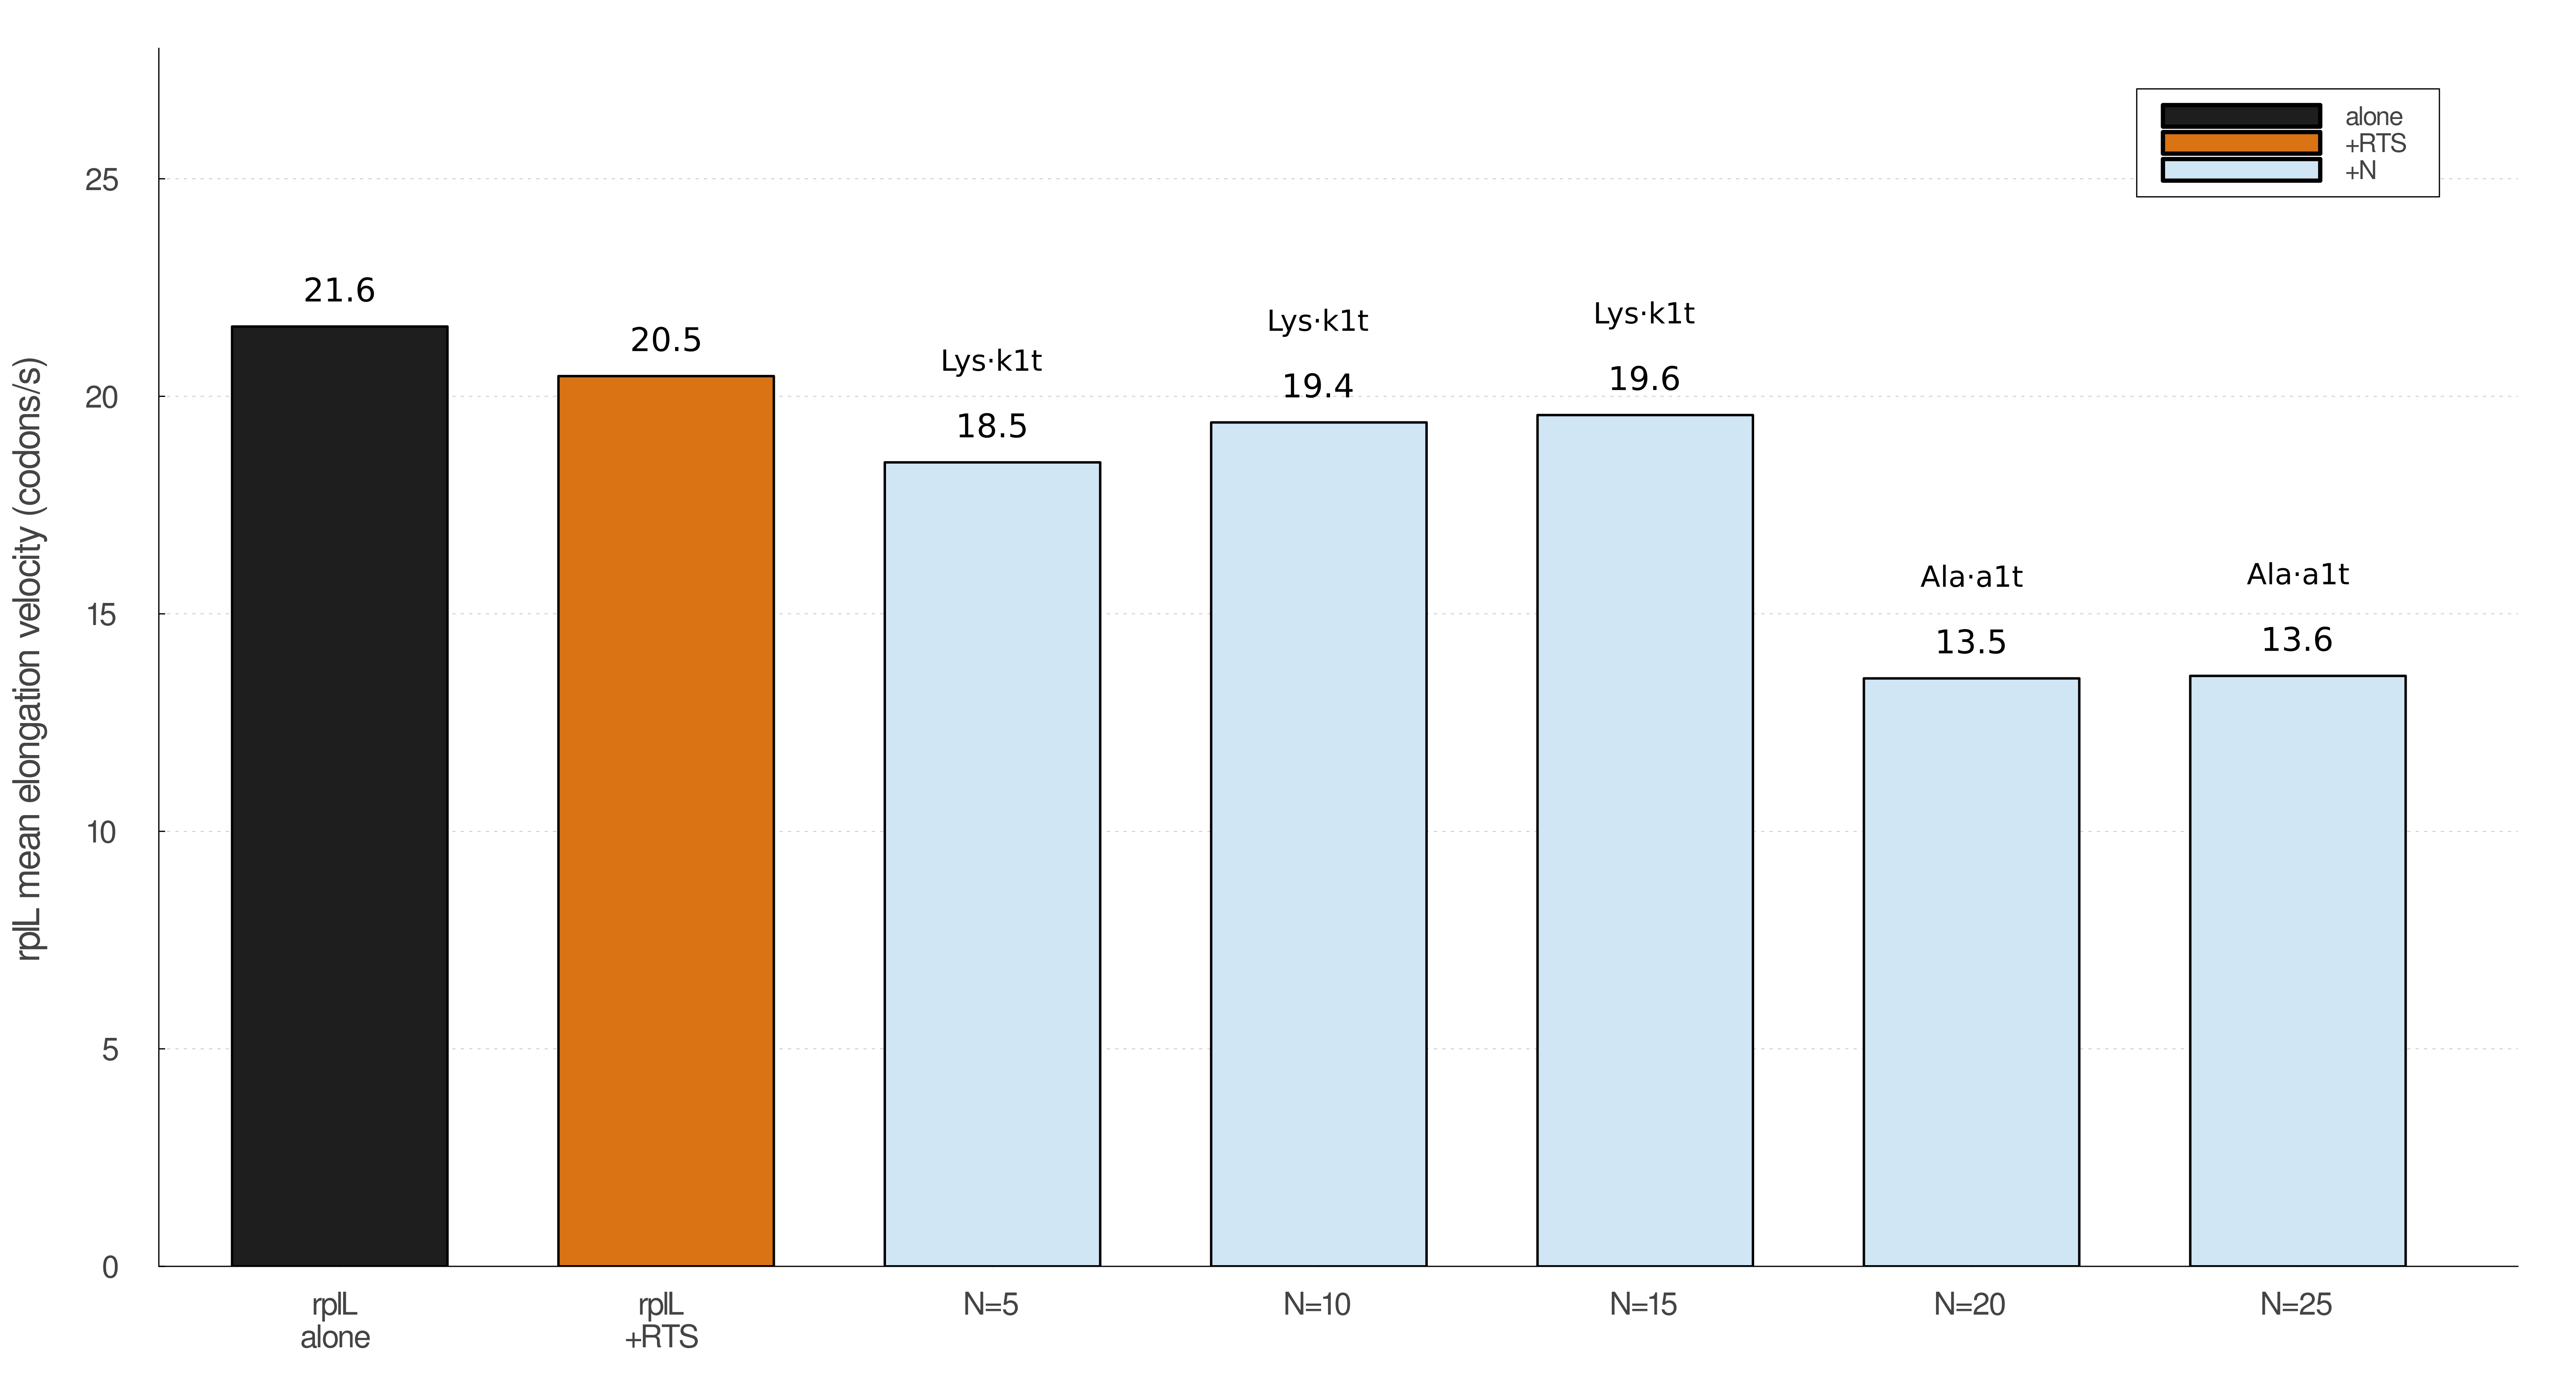

In [21]:
using DataFrames, CSV, Plots, Printf, Colors
gr()
default(dpi = 300, fontfamily = "Arial")

outdir = "../data/output"
mkpath(joinpath(outdir, "figures"))

trna_aa = Dict("a1t"=>"Ala","a2t"=>"Ala","k1t"=>"Lys","l1t"=>"Leu","l3t"=>"Leu",
               "s1t"=>"Ser","v1t"=>"Val","i1t"=>"Ile","t1t"=>"Thr","g3t"=>"Gly",
               "e2t"=>"Glu","r2t"=>"Arg","d1t"=>"Asp","n1t"=>"Asn","h1t"=>"His",
               "f1t"=>"Phe","p1t"=>"Pro","q2t"=>"Gln","y1t"=>"Tyr","c1t"=>"Cys")
trna_lab(t) = (t === missing || t == "") ? "" : string(get(trna_aa, String(t), "?"), "·", t)

refs    = CSV.read(joinpath(outdir, "spindler_rplL_rts_summary.csv"), DataFrame)
v_alone = refs[refs.case .== "alone", :mean_v][1]
v_rts   = refs[refs.case .== "rts",   :mean_v][1]

rs = CSV.read(joinpath(outdir, "run_summary_log.csv"), DataFrame)
approx(a, b; rtol = 1e-3) = abs(a - b) <= rtol * max(abs(b), 1.0)
rs = filter(r -> r.bg_mode == "first" && r.status == "ok" &&
            approx(r.V_IN_70SIC_scale, 75.0) && approx(r.ARS_scale, 20.0) &&
            approx(r.tRNA_scale, 1.0) && approx(r.Rib_scale, 1.0), rs)

bg_labels = String[]; bg_vel = Float64[]; bg_trna = String[]
for N in (5, 10, 15, 20, 25)
    sub = sort(filter(r -> r.N == N, rs), :timestamp)
    isempty(sub) && continue
    r = sub[end, :]
    push!(bg_labels, "N=$N")
    push!(bg_vel, r.rplL_mean_v_cs)
    push!(bg_trna, trna_lab(r.limiting_T3_name))
end

labels = vcat(["rplL\nalone", "rplL\n+RTS"], bg_labels)
vels   = vcat([v_alone, v_rts], bg_vel)
trnas  = vcat(["", ""], bg_trna)
n = length(vels); xi = collect(1:n)

# ── Three ACS-safe fills: distinct in COLOR and in GRAYSCALE (dark / mid / light) ──
#c_alone = RGB(0.15, 0.15, 0.15)   # ~15% gray when printed B/W
#c_rts   = RGB(0.55, 0.55, 0.55)   # ~55% gray
#c_bg    = RGB(0.82, 0.82, 0.82)   # ~82% gray
# Optional color version of the same luminance ladder (uncomment to use color print):
 c_alone = RGB(0.12, 0.12, 0.12)
 c_rts   = RGB(0.85, 0.45, 0.08)   # mid-luminance orange
 c_bg    = RGB(0.82, 0.90, 0.96)   # light blue

plt = plot(;
    size = (2100, 1140),
    dpi  = 300,
    fontfamily = "Helvetica",
    grid = :y,
    gridstyle = :dot,
    gridalpha = 0.30,
    ylims = (0, 28),
    legend = :topright,
    ylabel = "rplL mean elongation velocity (codons/s)",
    title  = "",
    xticks = (xi, labels),
    # force BLACK text (works when foreground_color_* keys fail)
    tickfont   = font(17, "Helvetica", :black),
    guidefont  = font(20, "Helvetica", :black),
    legendfont = font(14, "Helvetica", :black),
    background_color_legend = RGBA(1, 1, 1, 0.95),
    left_margin   = 12Plots.mm,
    bottom_margin = 14Plots.mm,
    top_margin    = 8Plots.mm,
    right_margin  = 10Plots.mm,
)

# Short legend labels so they fit the box; black outlines for print contrast
bar!(xi[1:1], vels[1:1]; bar_width = 0.66, c = c_alone, lc = :black, lw = 2.0,
     label = "alone")
bar!(xi[2:2], vels[2:2]; bar_width = 0.66, c = c_rts,   lc = :black, lw = 2.0,
     label = "+RTS")
bar!(xi[3:n], vels[3:n]; bar_width = 0.66, c = c_bg,    lc = :black, lw = 2.0,
     label = "+N")   # ALL N bars same color — no gradient, no hatch

for i in 1:n
    annotate!(i, vels[i] + 0.85,
              text(@sprintf("%.1f", vels[i]), 18, :black, :center))
    if trnas[i] != ""
        annotate!(i, vels[i] + 2.35,
                  text(trnas[i], 16, :black, :center))
    end
end

out = joinpath(outdir, "figures", "result1_velocity_limiting_trna.png")
savefig(plt, out)
println("Saved → ", out)
current()

## Cross-N analysis plots

Run after each simulation to refresh figures from the appendable logs.

Loaded 10656 rows from ../data/output/elongation_rate_log.csv
  N values   : [1, 5, 10, 15, 20, 25, 30, 40, 50]
  bg_modes   : String31["first", "BBaJ23108-rplS-4_first", "BBaJ23100-rplS-39_first", "BBaJ23100-rplS-18_first", "BBaJ23108-rplS-23_first", "BBaJ23108-rplS-47_first", "BBaJ23100-secA-19_first", "BBaJ23100-csrA-44_first", "BBaJ23100-rplS-48_first", "BBaJ23100-rplS-33_first", "BBaJ23100-rplS-45_first", "BBaJ23100-rplS-17_first", "BBaJ23100-rplS-6_first", "BBaJ23100-rplS-43_first", "BBaJ23108-rplS-1_first", "BBaJ23108-rplS-17_first", "BBaJ23100-rplS-42_first", "BBaJ23100-rplS-12_first", "BBaJ23100-rplS-47_first", "BBaJ23108-rplS-5_first", "BBaJ23100-rplS-37_first", "BBaJ23100-rplS-1_first", "BBaJ23100-rplS-7_first", "BBaJ23108-rplS-42_first", "BBaJ23108-rplS-38_first", "BBaJ23108-rplS-7_first", "BBaJ23100-rplS-24_first", "BBaJ23100-rplS-26_first", "BBaJ23100-rplS-13_first", "BBaJ23108-rplS-14_first", "BBaJ23108-rplS-40_first", "BBaJ23100-rplS-9_first", "BBaJ23100-rplS-19_first",

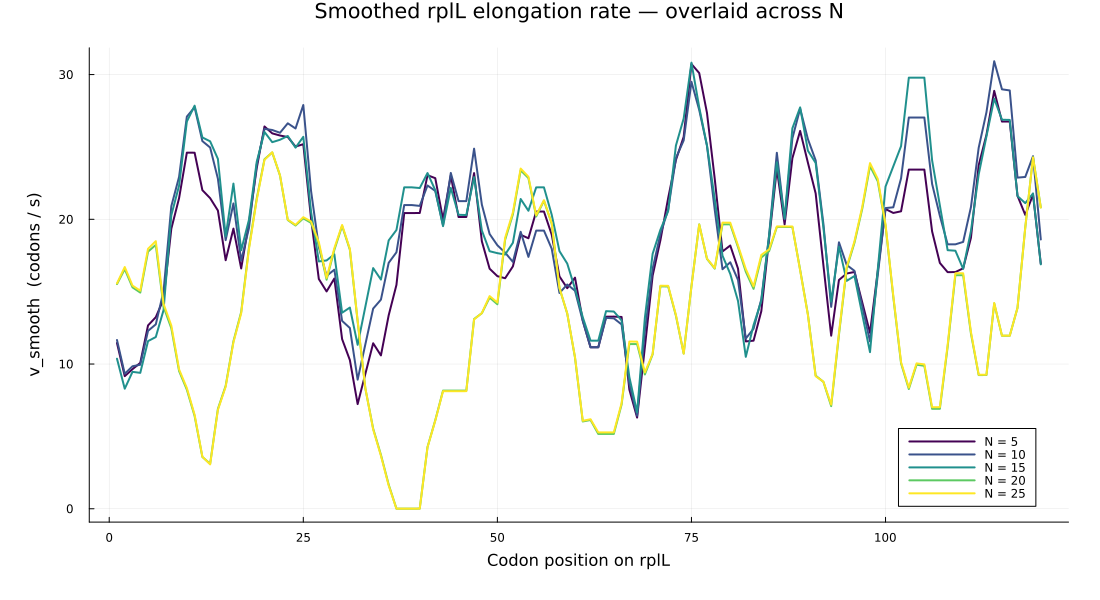

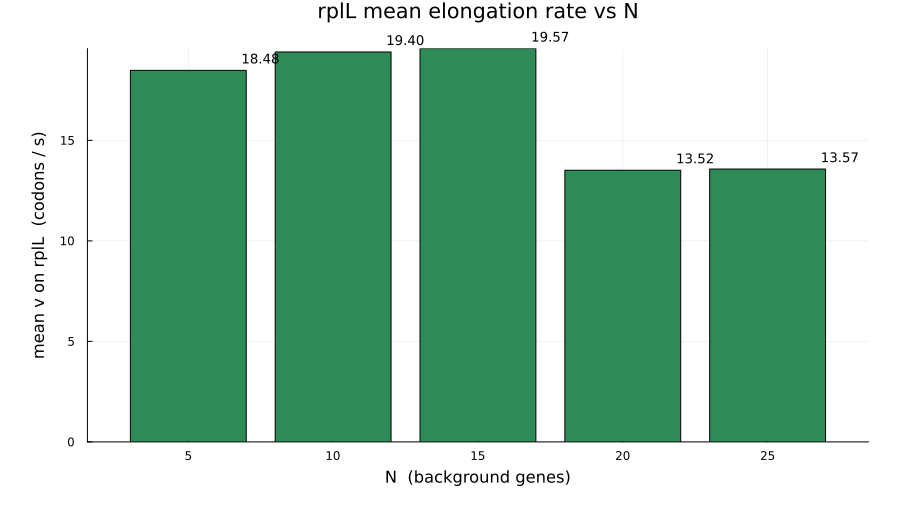

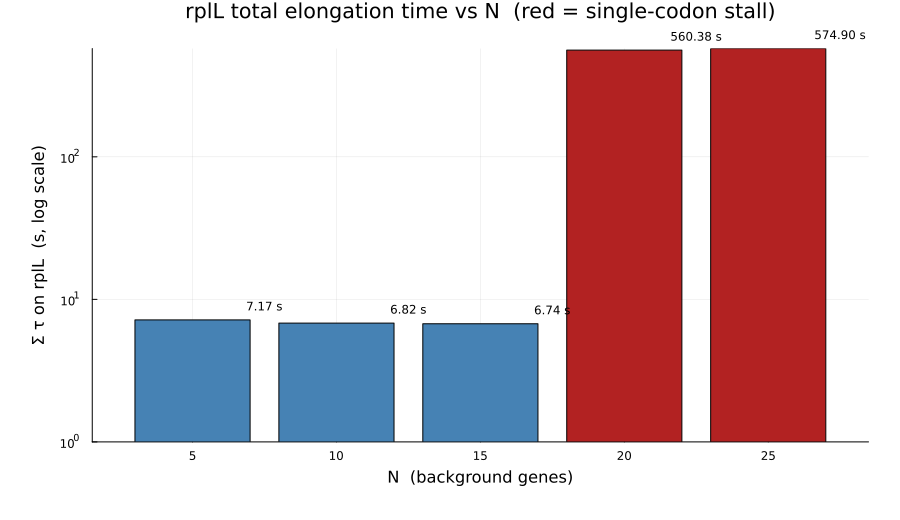

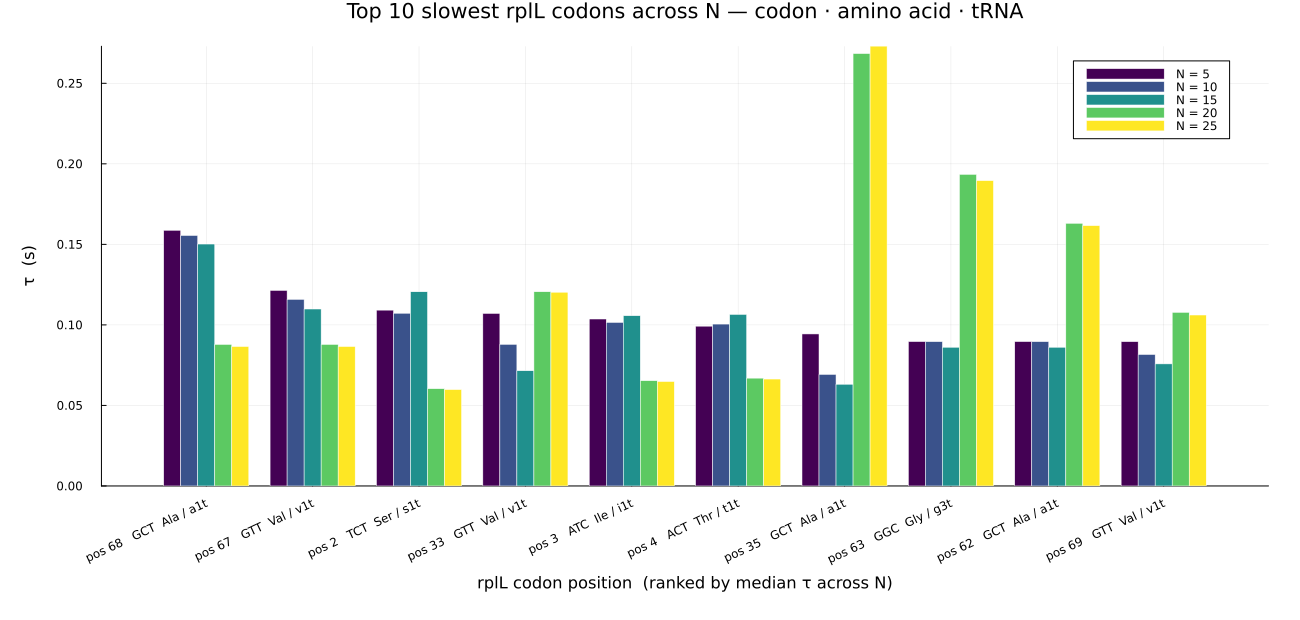

In [5]:
# ═══════════════════════════════════════════════════════════════════════════════
# Cross-N plots from the 100-min run-I sweep
#
# Reads the two appendable logs written by the simulation cell above:
#   ../data/output/elongation_rate_log.csv  — per-codon rows (120 per run)
#   ../data/output/run_summary_log.csv      — one row per run (params + key
#                                              metrics + limiting tRNA species)
#
# Produces three PNG figures into ../data/output/figures/ :
#   cross_N_v_smooth_profile.png   — v_smooth(codon) overlaid for all N
#   cross_N_sigma_tau_vs_N.png     — Σ τ on rplL vs N (invariance metric)
#   cross_N_slowest_codons.png     — top-K slowest rplL codons grouped by N
#
# Filters the log to the current run-I scale set so old/stale rows from earlier
# tuning configs are ignored. If the same N was re-run (e.g. for atol changes),
# only the LATEST timestamp for that N is plotted.
#
# Re-run this cell after every new simulation to refresh the figures.
# ═══════════════════════════════════════════════════════════════════════════════
using DataFrames, CSV, Plots, Statistics, Printf

elong_log_path       = "../data/output/elongation_rate_log.csv"
run_summary_log_path = "../data/output/run_summary_log.csv"
fig_dir              = "../data/output/figures"
isdir(fig_dir) || mkpath(fig_dir)

if !isfile(elong_log_path)
    error("Elongation log not found at $elong_log_path — run the simulation cell with status=ok at least once first.")
end

df = CSV.read(elong_log_path, DataFrame)
println("Loaded $(nrow(df)) rows from $(elong_log_path)")
println("  N values   : ", sort(unique(df.N)))
println("  bg_modes   : ", unique(df.bg_mode))
println("  V_IN_70SIC : ", unique(df.V_IN_70SIC_scale))
println("  ARS scales : ", unique(df.ARS_scale))
println("  tRNA scales: ", unique(df.tRNA_scale))
println("  EF scales  : ", unique(df.EF_scale))
println("  Rib scales : ", unique(df.Rib_scale))
println("  atol       : ", unique(df.ode_abstol))
println("  t_sample   : ", unique(df.t_sample_min))

# ─── Filter to the current run-I scale set ─────────────────────────────────────
# Strict run-I: V_IN_70SIC=20, V_IN_IF2D=2, ARS=20, tRNA=1.7, Rib=2 (EF=√Rib≈1.414).
# Adjust target_* values if you sweep a different config.
target_mode       = "first"
target_V_IN_70SIC = 75.0
target_V_IN_IF2D  = 2.0
target_ARS        = 20.0
target_tRNA       = 1.0
target_Rib        = 1.0

approx(a, b; rtol = 1e-3) = abs(a - b) <= rtol * max(abs(b), 1.0)

sub = filter(row ->
    row.bg_mode == target_mode &&
    approx(row.V_IN_70SIC_scale, target_V_IN_70SIC) &&
    approx(row.V_IN_IF2D_scale,  target_V_IN_IF2D)  &&
    approx(row.ARS_scale,        target_ARS)        &&
    approx(row.tRNA_scale,       target_tRNA)       &&
    approx(row.Rib_scale,        target_Rib),
    df)

@printf("\nFilter: mode=:%s  V_IN_70SIC=%.1f  V_IN_IF2D=%.1f  ARS=%.1f  tRNA=%.2f  Rib=%.1f\n",
        target_mode, target_V_IN_70SIC, target_V_IN_IF2D, target_ARS, target_tRNA, target_Rib)
@printf("  → %d rows match, N values %s\n",
        nrow(sub), string(sort(unique(sub.N))))

if isempty(sub)
    error("No rows match the filter — adjust target_* values above or run more simulations.")
end

# If the same N appears more than once (e.g. retries at different atol), keep the
# LATEST timestamp per N.
latest_ts = Dict{Any, String}()
for r in eachrow(sub)
    ts = string(r.timestamp)
    if !haskey(latest_ts, r.N) || ts > latest_ts[r.N]
        latest_ts[r.N] = ts
    end
end
sub = filter(row -> string(row.timestamp) == latest_ts[row.N], sub)

Ns = sort(unique(sub.N))
@printf("After de-duplication: plotting N = %s (latest run per N)\n", string(Ns))
@printf(">>> %d N-values will be plotted: %s   (if your new N is missing here, re-run this cell so the CSV is re-read)\n", length(Ns), string(Ns))

# ─── Per-N summary (scalar metrics) ────────────────────────────────────────────
per_N = combine(groupby(sub, :N)) do g
    g1 = sort(g, :codon_pos)[1, :]
    (
        N             = g1.N,
        sigma_tau_s   = g1.rplL_total_time_s,
        mean_v_cs     = g1.rplL_mean_v_cs,
        T3_min        = g1.T3_min,
        T3_mean       = g1.T3_mean,
        wall_time_s   = g1.wall_time_s,
        atol          = g1.ode_abstol,
        slowest_pos   = g.codon_pos[argmax(g.tau_s)],
        slowest_tau_s = maximum(g.tau_s),
    )
end
per_N = sort(per_N, :N)
println("\nPer-N summary:")
println(per_N)

# Viridis colour map: low N = purple, high N = yellow.
palette = cgrad(:viridis, max(length(Ns), 2); categorical = true)

# ─── PLOT 1: v_smooth profile overlaid for all N ───────────────────────────────
p_vsmooth = plot(
    xlabel = "Codon position on rplL",
    ylabel = "v_smooth  (codons / s)",
    title  = "Smoothed rplL elongation rate — overlaid across N",
    legend = :bottomright, size = (1100, 600),
    left_margin = 10Plots.mm, bottom_margin = 10Plots.mm,
    right_margin = 6Plots.mm, top_margin = 6Plots.mm,
)
for (i, N) in enumerate(Ns)
    d = sort(filter(r -> r.N == N, sub), :codon_pos)
    plot!(p_vsmooth, d.codon_pos, d.v_smooth_cod_s;
          label = "N = $N", linewidth = 2, color = palette[i])
end

# ─── PLOT 2a: mean v vs N — ROBUST headline metric (insensitive to single-codon stalls) ─
p_meanv = bar(
    string.(per_N.N), per_N.mean_v_cs;
    xlabel = "N  (background genes)",
    ylabel = "mean v on rplL  (codons / s)",
    title  = "rplL mean elongation rate vs N",
    legend = false, size = (900, 520), color = :seagreen,
    left_margin = 10Plots.mm, bottom_margin = 10Plots.mm,
    right_margin = 6Plots.mm, top_margin = 6Plots.mm,
)
let ymax = maximum(per_N.mean_v_cs)
    for (i, row) in enumerate(eachrow(per_N))
        annotate!(p_meanv, i, row.mean_v_cs + 0.03 * ymax,
                  text(@sprintf("%.2f", row.mean_v_cs), 9, :black))
    end
end

# ─── PLOT 2b: Σ τ vs N — LOG scale. Στ = Σ 1/v_i blows up on ANY single stalled codon,
#     so an N with one stall sits ~80x higher than the rest. Log keeps every N visible;
#     bars above STALL_S (stall regime) are drawn red so the artefact is explicit. ────────
STALL_S  = 50.0
sig_cols = [s > STALL_S ? :firebrick : :steelblue for s in per_N.sigma_tau_s]
p_sigma = bar(
    string.(per_N.N), per_N.sigma_tau_s;
    xlabel = "N  (background genes)",
    ylabel = "Σ τ on rplL  (s, log scale)",
    title  = "rplL total elongation time vs N  (red = single-codon stall)",
    legend = false, size = (900, 520), color = sig_cols, yscale = :log10,
    left_margin = 10Plots.mm, bottom_margin = 10Plots.mm,
    right_margin = 6Plots.mm, top_margin = 6Plots.mm,
)
for (i, row) in enumerate(eachrow(per_N))
    annotate!(p_sigma, i, row.sigma_tau_s * 1.25,
              text(@sprintf("%.2f s", row.sigma_tau_s), 8, :black))
end

# ─── PLOT 3: top-K slowest codons across N (grouped bars) ──────────────────────
top_k = 10
median_tau_per_pos = combine(groupby(sub, :codon_pos), :tau_s => median => :median_tau)
sort!(median_tau_per_pos, :median_tau, rev = true)
top_positions = median_tau_per_pos.codon_pos[1:min(top_k, nrow(median_tau_per_pos))]

# ─── Codon → amino acid → tRNA isoacceptor lookup ──────────────────────────────
# Source: data/input/AS_and_Codon.dat. The model's alpha_one (first cognate tRNA
# row that lists the codon) is reproduced by iterating TRNA_TABLE in order and
# returning the first match — same convention as alpha_struc_generation in
# functions.jl. Use this table to translate codon positions back to
# (codon, amino acid, tRNA isoacceptor) for human-readable plot/print labels.
TRNA_TABLE = [
    (tag = "a1t", aa = "Ala", codons = ["GCU", "GCA", "GCG"]),
    (tag = "a2t", aa = "Ala", codons = ["GCC"]),
    (tag = "c1t", aa = "Cys", codons = ["UGC", "UGU"]),
    (tag = "d1t", aa = "Asp", codons = ["GAC", "GAU"]),
    (tag = "e2t", aa = "Glu", codons = ["GAA", "GAG"]),
    (tag = "f1t", aa = "Phe", codons = ["UUC", "UUU"]),
    (tag = "g2t", aa = "Gly", codons = ["GGA", "GGG"]),
    (tag = "g3t", aa = "Gly", codons = ["GGC", "GGU"]),
    (tag = "h1t", aa = "His", codons = ["CAC", "CAU"]),
    (tag = "i1t", aa = "Ile", codons = ["AUC", "AUU", "AUA"]),
    (tag = "k1t", aa = "Lys", codons = ["AAA", "AAG"]),
    (tag = "l1t", aa = "Leu", codons = ["CUG"]),
    (tag = "l2t", aa = "Leu", codons = ["CUC", "CUU"]),
    (tag = "l3t", aa = "Leu", codons = ["CUA", "CUG"]),
    (tag = "l4t", aa = "Leu", codons = ["UUG"]),
    (tag = "l5t", aa = "Leu", codons = ["UUA", "UUG"]),
    (tag = "m1t", aa = "Met", codons = ["AUG"]),
    (tag = "n1t", aa = "Asn", codons = ["AAC", "AAU"]),
    (tag = "p1t", aa = "Pro", codons = ["CCG"]),
    (tag = "p2t", aa = "Pro", codons = ["CCC", "CCU"]),
    (tag = "p3t", aa = "Pro", codons = ["CCA", "CCU", "CCG"]),
    (tag = "q1t", aa = "Gln", codons = ["CAA"]),
    (tag = "q2t", aa = "Gln", codons = ["CAG"]),
    (tag = "r2t", aa = "Arg", codons = ["CGU", "CGC", "CGA"]),
    (tag = "r3t", aa = "Arg", codons = ["CGG"]),
    (tag = "r4t", aa = "Arg", codons = ["AGA"]),
    (tag = "r5t", aa = "Arg", codons = ["AGG"]),
    (tag = "s1t", aa = "Ser", codons = ["UCA", "UCU", "UCG"]),
    (tag = "s2t", aa = "Ser", codons = ["UCG"]),
    (tag = "s3t", aa = "Ser", codons = ["AGC", "AGU"]),
    (tag = "s5t", aa = "Ser", codons = ["UCC", "UCU"]),
    (tag = "t1t", aa = "Thr", codons = ["ACC", "ACU"]),
    (tag = "t2t", aa = "Thr", codons = ["ACG"]),
    (tag = "t4t", aa = "Thr", codons = ["ACA", "ACU", "ACG"]),
    (tag = "v1t", aa = "Val", codons = ["GUA", "GUG", "GUU"]),
    (tag = "v2t", aa = "Val", codons = ["GUC", "GUU"]),
    (tag = "w1t", aa = "Trp", codons = ["UGG"]),
    (tag = "y1t", aa = "Tyr", codons = ["UAC", "UAU"]),
]

# rplL coding sequence (same as cell 2). Codon positions 1..120 are translated;
# the trailing stop codon at position 121 (TAA) is not in the elongation log.
RPLL_CDS = "ATGTCTATCACTAAAGATCAAATCATTGAAGCAGTTGCAGCTATGTCTGTAATGGACGTTGTAGAACTGATCTCTGCAATGGAAGAAAAATTCGGTGTTTCCGCTGCTGCTGCTGTAGCTGTAGCTGCTGGCCCGGTTGAAGCTGCTGAAGAAAAAACTGAATTCGACGTAATTCTGAAAGCTGCTGGCGCTAACAAAGTTGCTGTTATCAAAGCAGTACGTGGCGCAACTGGCCTGGGTCTGAAAGAAGCTAAAGACCTGGTAGAATCTGCACCGGCTGCTCTGAAAGAAGGCGTGAGCAAAGACGACGCAGAAGCACTGAAAAAAGCTCTGGAAGAAGCTGGCGCTGAAGTTGAAGTTAAATAA"

codon_at_pos(seq, pos) = uppercase(String(seq[(3 * (pos - 1) + 1):(3 * pos)]))

function aa_trna_for_codon(codon_dna)
    codon_rna = replace(codon_dna, 'T' => 'U')
    for row in TRNA_TABLE
        codon_rna in row.codons && return (codon = codon_dna, codon_rna = codon_rna,
                                            aa = row.aa, trna = row.tag)
    end
    return (codon = codon_dna, codon_rna = codon_rna, aa = "?", trna = "?")
end

top_info = [(; pos = p, median_tau_s = median_tau_per_pos.median_tau[i],
              aa_trna_for_codon(codon_at_pos(RPLL_CDS, p))...)
            for (i, p) in enumerate(top_positions)]

println("\nTop $(top_k) slowest rplL codon positions  (ranked by median τ across N=", Ns, "):")
@printf("  %-5s %-5s %-7s %-5s %-5s %-12s\n", "rank", "pos", "codon", "aa", "tRNA", "median τ (s)")
for (rank, info) in enumerate(top_info)
    @printf("  %-5d %-5d %-7s %-5s %-5s %-12.4f\n",
            rank, info.pos, info.codon, info.aa, info.trna, info.median_tau_s)
end

nN          = length(Ns)
bw          = 0.8 / nN
xpos_centre = collect(1:length(top_positions))

p_slow = plot(
    size   = (1300, 620),
    xlabel = "rplL codon position  (ranked by median τ across N)",
    ylabel = "τ  (s)",
    title  = "Top $top_k slowest rplL codons across N — codon · amino acid · tRNA",
    legend = :topright,
    xrotation = 25, xtickfontsize = 8,
    left_margin = 10Plots.mm, bottom_margin = 18Plots.mm,
    right_margin = 6Plots.mm, top_margin = 6Plots.mm,
)
for (i, N) in enumerate(Ns)
    xs   = Float64[]
    taus = Float64[]
    for (j, pos) in enumerate(top_positions)
        rowf = filter(r -> r.N == N && r.codon_pos == pos, sub)
        push!(xs,   xpos_centre[j] + (i - (nN + 1) / 2) * bw)
        push!(taus, isempty(rowf) ? NaN : first(rowf.tau_s))
    end
    bar!(p_slow, xs, taus;
         label = "N = $N", bar_width = bw,
         color = palette[i], linewidth = 0.5, linecolor = :white)
end
slow_labels = ["pos $(info.pos)   $(info.codon)  $(info.aa) / $(info.trna)" for info in top_info]
xticks!(p_slow, (xpos_centre, slow_labels))

# ─── Save and display ──────────────────────────────────────────────────────────
vsmooth_path = "$fig_dir/cross_N_v_smooth_profile.png"
meanv_path   = "$fig_dir/cross_N_mean_v_vs_N.png"
sigma_path   = "$fig_dir/cross_N_sigma_tau_vs_N.png"
slow_path    = "$fig_dir/cross_N_slowest_codons.png"
savefig(p_vsmooth, vsmooth_path)
savefig(p_meanv,   meanv_path)
savefig(p_sigma,   sigma_path)
savefig(p_slow,    slow_path)

println("\nSaved 4 figures:")
println("  1. v_smooth profile (all N) → $vsmooth_path")
println("  2. mean v vs N (robust)     → $meanv_path")
println("  3. Σ τ vs N (log)           → $sigma_path")
println("  4. top-$top_k slowest codons   → $slow_path")

# Display all inline.
display(p_vsmooth)
display(p_meanv)
display(p_sigma)
display(p_slow)

# Optional: peek at the run summary log (limiting tRNA per run) if it exists.
if isfile(run_summary_log_path)
    rs = CSV.read(run_summary_log_path, DataFrame)
    println("\nrun_summary_log peek (latest 8 rows):")
    show(stdout, "text/plain",
         last(sort(rs, :timestamp), min(nrow(rs), 8))[!, [:timestamp, :N, :status,
              :rplL_total_time_s, :rplL_mean_v_cs, :T3_mean, :T3_min,
              :limiting_T3_name, :limiting_T3_uM, :ode_abstol, :wall_time_s]])
    println()
end

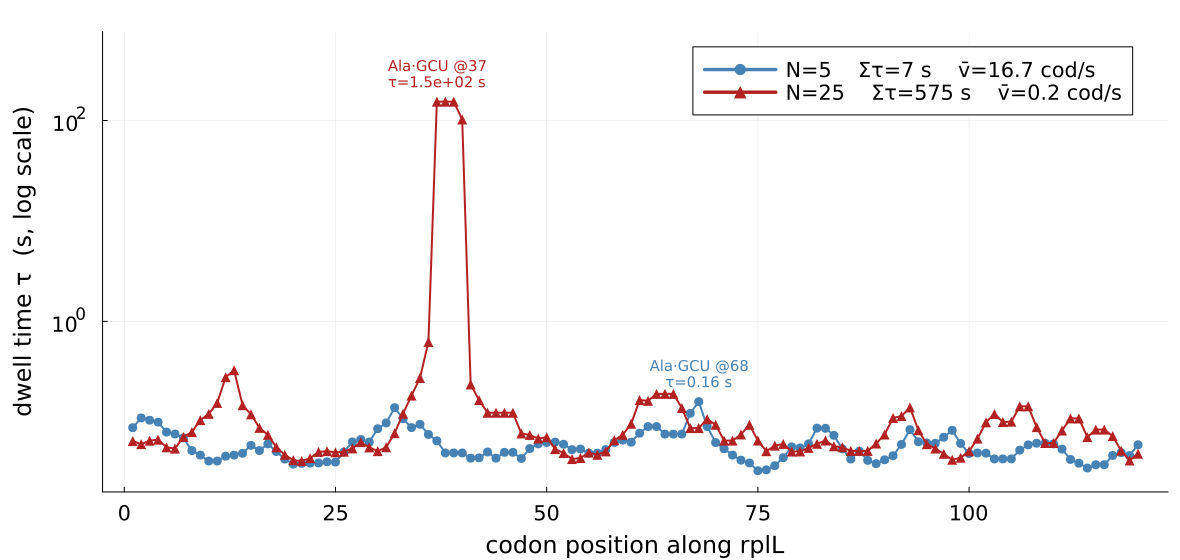

In [1]:
using DataFrames, CSV, Plots, Printf
gr()
outdir = "../data/output"

ref      = CSV.read(joinpath(outdir, "spindler_rplL_rts_codon_detail.csv"), DataFrame)
codon_of = Dict(ref.pos .=> ref.codon)

# minimal genetic code so the peak label shows the amino acid
const GCODE = Dict(
 "TTT"=>"Phe","TTC"=>"Phe","TTA"=>"Leu","TTG"=>"Leu","CTT"=>"Leu","CTC"=>"Leu","CTA"=>"Leu","CTG"=>"Leu",
 "ATT"=>"Ile","ATC"=>"Ile","ATA"=>"Ile","ATG"=>"Met","GTT"=>"Val","GTC"=>"Val","GTA"=>"Val","GTG"=>"Val",
 "TCT"=>"Ser","TCC"=>"Ser","TCA"=>"Ser","TCG"=>"Ser","CCT"=>"Pro","CCC"=>"Pro","CCA"=>"Pro","CCG"=>"Pro",
 "ACT"=>"Thr","ACC"=>"Thr","ACA"=>"Thr","ACG"=>"Thr","GCT"=>"Ala","GCC"=>"Ala","GCA"=>"Ala","GCG"=>"Ala",
 "TAT"=>"Tyr","TAC"=>"Tyr","CAT"=>"His","CAC"=>"His","CAA"=>"Gln","CAG"=>"Gln","AAT"=>"Asn","AAC"=>"Asn",
 "AAA"=>"Lys","AAG"=>"Lys","GAT"=>"Asp","GAC"=>"Asp","GAA"=>"Glu","GAG"=>"Glu","TGT"=>"Cys","TGC"=>"Cys",
 "TGG"=>"Trp","CGT"=>"Arg","CGC"=>"Arg","CGA"=>"Arg","CGG"=>"Arg","AGT"=>"Ser","AGC"=>"Ser","AGA"=>"Arg",
 "AGG"=>"Arg","GGT"=>"Gly","GGC"=>"Gly","GGA"=>"Gly","GGG"=>"Gly")
aa_of(cdn) = get(GCODE, uppercase(String(cdn)), "?")

load_tau(N) = (d = CSV.read(joinpath(outdir, "spindler_rplL_N$(N)_first_codon_detail.csv"), DataFrame);
               (d.codon, d.tau_s))

Ns   = [5, 25]
cols = Dict(5 => :steelblue, 25 => :firebrick)
mk   = Dict(5 => :circle,    25 => :utriangle)     # B/W-safe: circle vs triangle

τpeak = maximum(vcat([load_tau(N)[2] for N in Ns]...))

plt = plot(; size = (1180, 560), yscale = :log10,
    xlabel = "codon position along rplL",
    ylabel = "dwell time τ  (s, log scale)",
    legend = :topright, legendfontsize = 14,
    guidefontsize = 16, tickfontsize = 14,          # bigger axis label + tick fonts
    ylims = (0.02, τpeak * 5),
    left_margin = 8Plots.mm, bottom_margin = 6Plots.mm, top_margin = 6Plots.mm)

for N in Ns
    pos, tau = load_tau(N)
    Στ = sum(tau); L = maximum(pos)
    plot!(pos, tau; lw = 2, c = cols[N], marker = mk[N], ms = 5, msc = cols[N],
          label = @sprintf("N=%d    Στ=%.0f s    v̄=%.1f cod/s", N, Στ, L / Στ))
    j = argmax(tau); p = pos[j]
    cdn = replace(get(codon_of, p, "?"), "T" => "U")
    aa  = aa_of(get(codon_of, p, "?"))
    annotate!(p, tau[j] * 1.9,
              text(@sprintf("%s·%s @%d\nτ=%.2g s", aa, cdn, p, tau[j]), 10, cols[N], :center))
end

savefig(joinpath(outdir, "figures", "result2_dwell_profile_N5_N25.png"))
current()

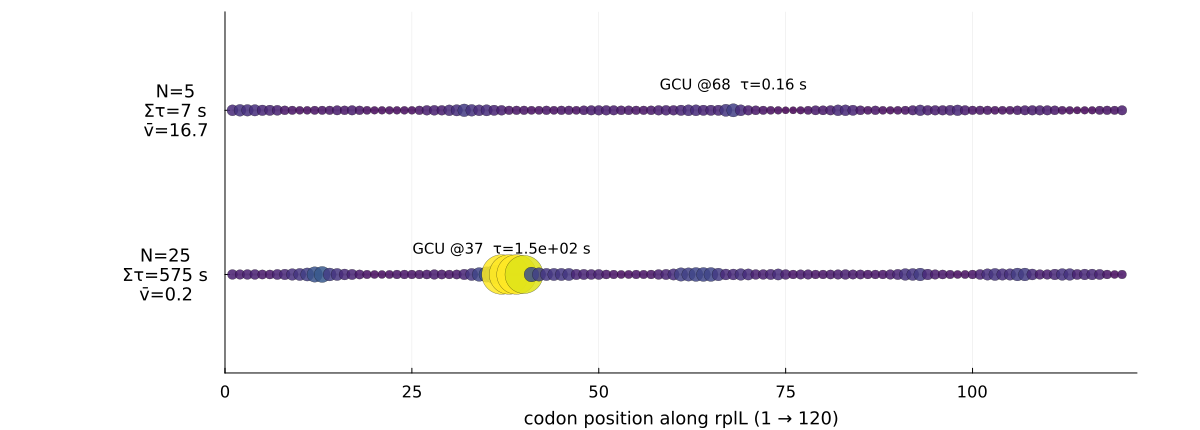

In [2]:
using DataFrames, CSV, Plots, Printf
gr()
outdir = "../data/output"

ref      = CSV.read(joinpath(outdir, "spindler_rplL_rts_codon_detail.csv"), DataFrame)
codon_of = Dict(ref.pos .=> ref.codon)
load_tau(N) = (d = CSV.read(joinpath(outdir, "spindler_rplL_N$(N)_first_codon_detail.csv"), DataFrame);
               (d.codon, d.tau_s))

Ns     = [5, 25]
tracks = [(N, load_tau(N)...) for N in Ns]

# shared log range → size AND color are comparable across BOTH tracks
allτ   = vcat([t[3] for t in tracks]...)
lo, hi = log10(minimum(allτ)), log10(maximum(allτ))
sz(τ)  = 4 .+ 18 .* (clamp.(log10.(τ), lo, hi) .- lo) ./ (hi - lo)

L       = maximum(tracks[1][2])
ylabels = [@sprintf("N=%d\nΣτ=%.0f s\nv̄=%.1f", N, sum(tau), L / sum(tau)) for (N, pos, tau) in tracks]

plt = plot(; size = (1200, 430),
    xlabel = "codon position along rplL (1 → $L)",
    yticks = (1:length(tracks), reverse(ylabels)), ytickfontsize = 12,
    guidefontsize = 12, tickfontsize = 11,
    ylims = (0.4, length(tracks) + 0.6), xlims = (0, L + 2),
    legend = false, grid = :x, colorbar_title = "log₁₀ τ  (s)",
    left_margin = 30Plots.mm, bottom_margin = 6Plots.mm, right_margin = 10Plots.mm)

    for (k, (N, pos, tau)) in enumerate(tracks)
        y = length(tracks) - k + 1                              # N=5 on top → N=25 bottom
        plot!([1, L], [y, y]; lc = :gray80, lw = 2, label = "")               # backbone
        scatter!(pos, fill(y, length(pos));
                 ms = sz(tau), marker_z = log10.(tau), clims = (lo, hi),
                 c = :viridis, markerstrokewidth = 0.3, ma = 0.85, label = "")
        j = argmax(tau); p = pos[j]
        cdn = replace(get(codon_of, p, "?"), "T" => "U")
        annotate!(p, y + 0.16, text(@sprintf("%s @%d  τ=%.2g s", cdn, p, tau[j]), 10, :black, :center))
    end

savefig(joinpath(outdir, "figures", "result2_dotplot_N5_N25.png"))
current()

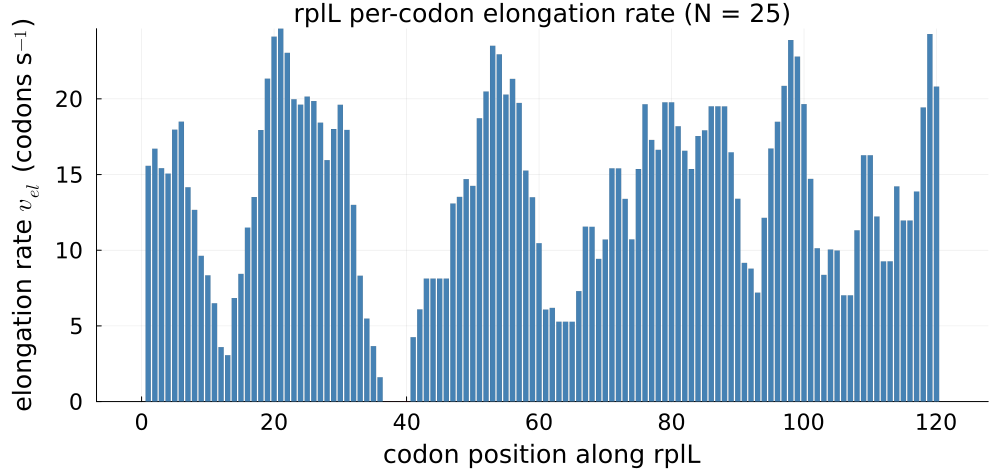

"e:\\TxTl_v2_main\\TXTLv2\\data\\output\\figures\\N25_codon_elongation_rate.png"

In [3]:
using Plots, Printf, CSV, DataFrames
using LaTeXStrings                     # for a proper v_el symbol (optional)

d     = CSV.read("../data/output/spindler_rplL_N25_first_codon_detail.csv", DataFrame)
stall = d.tau_s .> 10.0
cols  = [s ? :crimson : :steelblue for s in stall]

p2 = bar(d.codon, d.v_codons_s; color = cols, legend = false, lw = 0,
         xlabel = "codon position along rplL",
         ylabel = L"elongation rate $v_{el}$ (codons s$^{-1}$)",
         title  = "rplL per-codon elongation rate (N = 25)",
         guidefontsize = 17, tickfontsize = 15, titlefontsize = 17,
         size = (1000, 470), left_margin = 8Plots.mm, bottom_margin = 6Plots.mm)

display(p2)
savefig(p2, "../data/output/figures/N25_codon_elongation_rate.png")

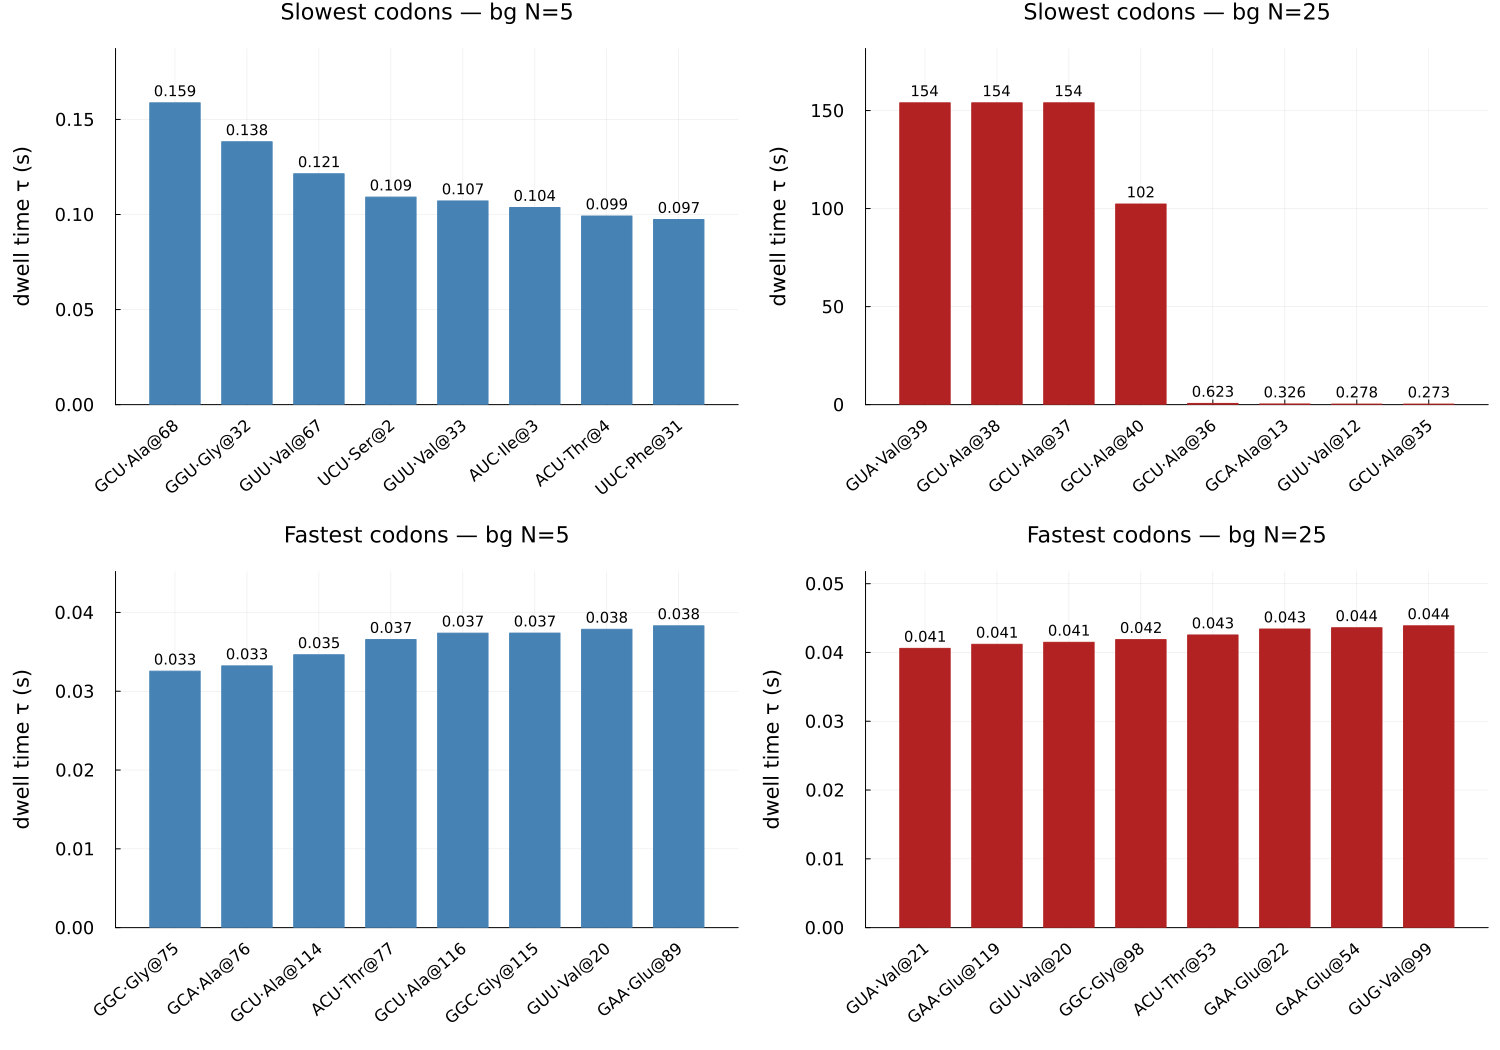

In [4]:
using Plots, Printf, CSV, DataFrames
gr()
outdir = "../data/output"

# ── genetic code (DNA) → amino acid ──
const BASES = "TCAG"
const AAS   = "FFLLSSSSYY**CC*WLLLLPPPPHHQQRRRRIIIMTTTTNNKKSSRRVVVVAAAADDEEGGGG"
gcode = Dict{String,Char}()
let i = 1
    for a in BASES, b in BASES, c in BASES
        gcode[string(a, b, c)] = AAS[i]; i += 1
    end
end
aa3 = Dict('A'=>"Ala",'R'=>"Arg",'N'=>"Asn",'D'=>"Asp",'C'=>"Cys",'Q'=>"Gln",
           'E'=>"Glu",'G'=>"Gly",'H'=>"His",'I'=>"Ile",'L'=>"Leu",'K'=>"Lys",
           'M'=>"Met",'F'=>"Phe",'P'=>"Pro",'S'=>"Ser",'T'=>"Thr",'W'=>"Trp",
           'Y'=>"Tyr",'V'=>"Val",'*'=>"Stop")

ref      = CSV.read(joinpath(outdir, "spindler_rplL_rts_codon_detail.csv"), DataFrame)
codon_of = Dict(ref.pos .=> String.(ref.codon))
read_tau(N) = (d = CSV.read(joinpath(outdir, "spindler_rplL_N$(N)_first_codon_detail.csv"), DataFrame);
               Dict(d.codon .=> d.tau_s))
t5, t25 = read_tau(5), read_tau(25)

lab(p) = (cdn = get(codon_of, p, "?");
          @sprintf("%s·%s@%d", replace(cdn, "T" => "U"),
                   string(get(aa3, get(gcode, cdn, '?'), "?")), p))

function rank_panel(tau, ttl, col; slow = true, k = 8)
    ps   = sort(collect(keys(tau)); by = p -> tau[p], rev = slow)[1:k]
    xs   = collect(1:k)
    vals = [tau[p] for p in ps]
    plt = bar(xs, vals; c = col, lc = col, legend = false, bar_width = 0.7,
        title = ttl, titlefontsize = 15, guidefontsize = 14, tickfontsize = 12,
        xticks = (xs, lab.(ps)), xrotation = 40, xtickfontsize = 11,
        ylabel = "dwell time τ (s)", ylims = (0, maximum(vals) * 1.18),
        left_margin = 13Plots.mm, bottom_margin = 22Plots.mm)
    for (x, v) in zip(xs, vals)
        annotate!(plt, x, v + maximum(vals) * 0.04,
                  text(v < 1 ? @sprintf("%.3f", v) : @sprintf("%.0f", v), 10, :black, :center))
    end
    return plt
end

p_s5  = rank_panel(t5,  "Slowest codons — bg N=5",  :steelblue; slow = true)
p_s25 = rank_panel(t25, "Slowest codons — bg N=25", :firebrick; slow = true)
p_f5  = rank_panel(t5,  "Fastest codons — bg N=5",  :steelblue; slow = false)
p_f25 = rank_panel(t25, "Fastest codons — bg N=25", :firebrick; slow = false)

fig = plot(p_s5, p_s25, p_f5, p_f25; layout = (2, 2), size = (1500, 1050),
           left_margin = 8Plots.mm, bottom_margin = 10Plots.mm, top_margin = 5Plots.mm)
savefig(fig, joinpath(outdir, "figures", "result3_codon_compare_4panel.png"))
current()

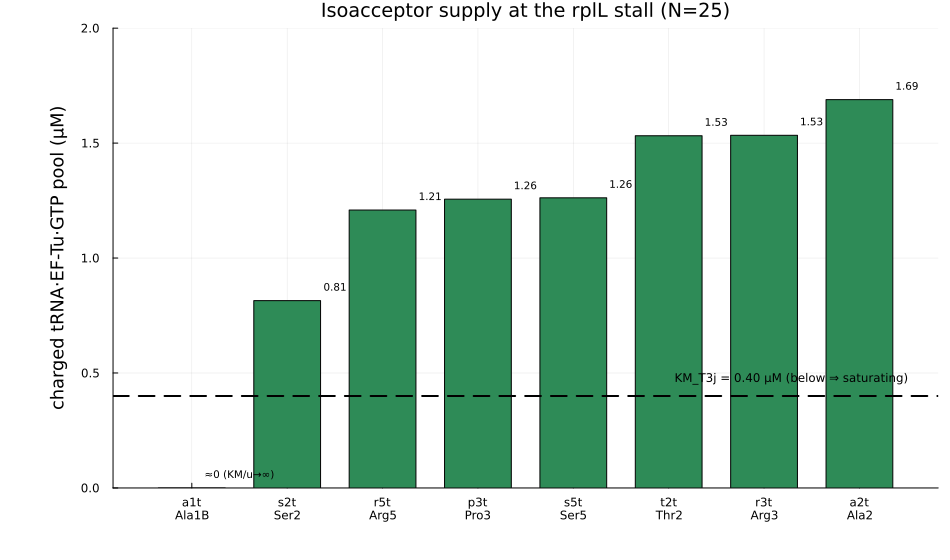

In [5]:
using Plots, Printf
gr()
outdir = "../data/output"; KM = 0.40        # KM_T3j on the primary block (µM), from the N=25 report

sp  = ["a1t\nAla1B","s2t\nSer2","r5t\nArg5","p3t\nPro3","s5t\nSer5","t2t\nThr2","r3t\nArg3","a2t\nAla2"]
u   = [0.0, 0.8147, 1.2088, 1.2560, 1.2620, 1.5320, 1.5340, 1.6890]
cols = [v <= KM ? :firebrick : (v <= 2KM ? :orange : :seagreen) for v in u]

bar(sp, u; c=cols, legend=false, ylims=(0, 2.0), size=(950,560),
    ylabel="charged tRNA·EF-Tu·GTP pool (µM)", bar_width=0.7,
    title="Isoacceptor supply at the rplL stall (N=25)",
    guidefontsize=12, titlefontsize=13,
    left_margin=15Plots.mm, bottom_margin=10Plots.mm)     # ← left_margin fixes the clipped y-label
hline!([KM]; lc=:black, ls=:dash, lw=2)
annotate!(8.0, KM+0.08, text("KM_T3j = 0.40 µM (below ⇒ saturating)", 8, :right, :black))
for i in eachindex(u)
    annotate!(i, u[i]+0.06, text(u[i]==0 ? "≈0 (KM/u→∞)" : @sprintf("%.2f", u[i]), 7, :center))
end
savefig(joinpath(outdir,"figures","result2_isoacceptor_supply.png")); current()

# Spindler ACS RTS comparsion part

In [8]:
# ─── Packages, functions ───
include("packages.jl")
using DataFrames, CSV, Printf, Plots
include("functions.jl")
gr()

# ─── Sequences ───
rplL_seq = "ATGTCTATCACTAAAGATCAAATCATTGAAGCAGTTGCAGCTATGTCTGTAATGGACGTTGTAGAACTGATCTCTGCAATGGAAGAAAAATTCGGTGTTTCCGCTGCTGCTGCTGTAGCTGTAGCTGCTGGCCCGGTTGAAGCTGCTGAAGAAAAAACTGAATTCGACGTAATTCTGAAAGCTGCTGGCGCTAACAAAGTTGCTGTTATCAAAGCAGTACGTGGCGCAACTGGCCTGGGTCTGAAAGAAGCTAAAGACCTGGTAGAATCTGCACCGGCTGCTCTGAAAGAAGGCGTGAGCAAAGACGACGCAGAAGCACTGAAAAAAGCTCTGGAAGAAGCTGGCGCTGAAGTTGAAGTTAAATAA"

rts_seqs = Dict(
    "C_eCU_1" => "ATGCGTCCGTCTTTCCATACTCGCCGTTCTTGGGCAGCGCAGGTCAACGTGAAAGCCGGCGGTACGGCTGCGTGTAAACTGCAAGACGCTCAGTTCCGTGTGTACTATCTGTCTATCCGCGGCCCGAGCCACGAGGTCAATGTTGGTGACAAGGACAATCTGGTCGCAGGCGGTCGCATCGATCTGGAGGCCATCGCACGTATCGAAAAAACGGGCCTGTTCAAACTCGATCGATTGGCAAAAGACTTCTTCCGCGCGTTCGGTGAAGTGCCAGGTATGCTTGCGATTATCTTAGAAGTATATCACCAGTATGGTATTGGCTGGGGCTTAGCATCCTCCAGCGCGCAGCGTGACAGTGGAAGCGAACTGGAACGTTCTGCTGTGAACGAACGTAATTCGACCACTTGCCGTGACCAGTGTGATCGCATGAACGCTCGTATTGGCATGGCTGGTAAACAGCCGGAATTCAATACGGTGGGAACCGGCAAGCGCAACTTCGGCGACGTATCGCAATACGGCCGTTTGCAGCATATTATCGAAGCTGGCGCAAAAATGGCCCTGGCCCGCCGTACTGACCATGACGGTGTTGCGAAGGAGACGTTGGTTGCCGAAGAGATTACATACGATACCACCCTGGTGCGCGGTACCATAGTTGAAGCTCAAGAAGTTAGCCCAGACTATACTCCTGCTGCGGGCCAGGTGGAGCTGTCGACGTATCTCGCTCTGTCAGGTAAACGTGATGACCAATTTGGTTTTTTAGGGGAAAACACACCGGCTGGCTTTAAAGTTAAAACCATCGATCATGGTTTTTACAACATCGCGAACCGTGAAAACGTGCTGTGGCAGGCGGTCTCTTCCGAAGAAAGCGAGAAAGTGAATCTGCTGTTGCCGCCTCCGATGAAAACCTGGACTCAAAGCGATACCTGGCTGAAAATTGAACTGAGTCGCCCGTCCCCGATTCAAGTCGGTGACAGCATGGGCCACGCAGATCGCGTCACAGCTTTTGCCCCCACCCGTGCGAACACCCGTGAGCTGCAGAAACAAGCACTGGTTGGTATTATCAAAGATTTTTACGACATCCGTCGCGTGAAACTGGCAAACCCCTTTCAGGATGTGGATGTTATCGTGATGGAAGTAGATCTTCCGCCGGCCATCAAAATCGTTGGGTGCGGGCTGACCTACATTGTACACTTACAGGAAGTTCCGGCTCCAAACCTGAATATTGGTTCATTTCAGTACGGTGATTATCTTGTTAAGACCATGGTTATCGAGGCGCGCGCCAAGCTCCCTGGTCTCTTCCTGAAAGATATGTTGATGGGAGCATGCAATAAAAAGAACAAACCGGCGGCCAAAATGTACCTGCCACCGTCCTTCAGTGCGGCGAGCGAAAACGGCCAGCTGCATGAATCTAACCACATGAAATTCCTGGCAGAACTTGGCGTCGATCTCCAGAAAATCGAGGTTTTTGATGAAATCCTGGAACACAACGATATTTCACTGCTAACTGTTTGGCTGATTGCCACTGCGACCACCTATCGGGAGGGCATTTTACTGGTAAAAGTACAGCTGGAATCTGCCGTAGTGAGAATCCTGCCGGACGCGCTGGCCGCGGGGATCACCGAAAAGGAACTGGAAGGTGGCGCGTCCGCAATGATTGGTGCTGTAGTTACGCAGTAA",
    "C_eCU_2" => "ATGTCTGCTGGGCCAACAGGTAACGTTCTGAAATTCGCTCTGGACCCGGAATATGAGATCATCTACGCCGGTCCTCAAGTGGATTTAGCCAACATTGCGTGCGTCTTTGCGTCAGCGCCGAACGATAACGCGCGTAACGTAGTTGCATTTGGTAGCGGCGCTGATATCGAAGGTTTCCTTATGACCCGCGGCGCCCAGAATGAAGCGATGGGGACCCTGCTGGATGAACCAAAAGAAGACGGTAAGATGGGCACGATTAAAATCGTACTGCAAATGAAGGCAGAGGACTTGTTCCGTGATGCCAGCAACACTGTGGCACGCAAAATCGATTTCATACACGAAGGCGTGAAAGGCTTCTACGAGGGGCAGGTGAAACAGTACCTTGCTGGTTCCAAGCCCGCAACCATTACCCGTACGGACCGTACAGATGGTGGTGCATACGAACAGCGGGAGTTGGATTTGTACATGATCGACAACCGTATCATCGCGGCTTCTAACAAATCCCAGGATATTCACGCAGAGGTTGTTGGCGGCACACACACTGAAACCTTAAAACGCGTTGAGGTTTGGTGGCCGGACCAAGCTCACTACTTTGCCAGCCTGATCCGCGCCATGCTGCGTGTCGAAGATGCGTATAAACGCCCGCAGCCGGACATGGAGGCCGCACTGCATGGTTACTGGCTGTCCAACCTGGAAAGAAAAGGCTCGTCCGATGTTTTTGACAAAAGTTTGCAAGGAGCGCTTCTGATTGCACATGCGGGTAAAACTTGTGGCACGAACCCGACTCCGGGTACCGTTGCGTATATTGTGACCTTCCCGTTCCGCGAAAAATTCATCCCGGAGGTGTATCTGATTCTGGAACGTGTTCTGTCTGAAGGTCGTATGAATGAAGGTCGTTTTGTGCAGTGGAACGATAAAGCTATTACTGTGGGCGAAGGCCTGGCGGAAGGAACCCAATCAAAGTTGTTTAAAAGTCTGGCTCTGTTACGAACTCCAGAAACCCTGTCCGTTCATCTGGAAATTTATCAGCGCGTCCGCGGTCCGCAGATCGTTGGCCTGGGTCCCATGTTTGACATTACGATCGCTTGCCAGGTGACCGCGAATGTCCCGTCGGTCCGTTATCTGATCCTGTTACTGCAGAGTCCTACCCAGCACGTACGTAACATGCTGAAAGCGCAGATTGACTCTCAATTTCTAATCCTGCGTAGCAAAGTGAAACACCTCGCTACCGGACGCCTCGGTCAACAGGTTAAATATGATGAACTGAAGTCTATCACCGCGTTCACCATGACGCAGGAAGCACGCGATGGTCCTGAAGGCTGCCTGTGTTTCCTCGTAAGCAAAATCTCACGCGCCGCACTTGATGCTGACCATGATCTGAAACCGTTAAATATGGTACTGTTCGCCATCGCTACCAAGCTGGGCCGCCCGGTTCTCGACCTGAAAATTGCAGAAGAAGTCAAAGAAAATGGCGTAAACGATGAGGGCACTAACGTAGCGGGTCGTTTTACGTACGCCGCTCTGGCAGGGGAGGTGCCGCGTTCTATTGAAGTTAATCAGCAGGACAGCGCGGGCGAAATGGCCCTCATTCGTAAAGAAAATTGGGGCGGTTGGTCGAACAAGGCGGACGTGCCAGTCGTAGCGGTGAGCCATTCCTCTGCCGTTATCAGCCGTTAA",
    "C_eCU_3" => "ATGGCAGTCGTTGAGTTCGAACAACCCTATCAGATGAAAGATGTGACCATGGCATGCGTAGCTGGTGACCATGCATTGCTTGGCGTCAAACTGATTCTGTTCGAACAGATGGGTCGTGGCAATGCTACCGCTTCAGTTACTCGTTCTAACAAAGGTCGCTTGGCCTTAATGGACTCCCCGTTAGGAGTGGGTGTGTACATCGCGAAACAGGAACTGCCTGAAAAGCAGGGGGACGTGTTTGCCTTCCTGTTCCAGCAGAATGAACCAGAATTCGGCCTGCAGGTTGCGGCGGATCTGGAGCGCCAGATGACGATTGTAAAGGATCCGGCACTGGAGTACATCCCAGCCCGCGGCAGATACAAGAAATATATCGCACTCTGGATTCAGGATGCAGCAGAAGGCGGTGTAAGCGACGCCGAAGCGGCTCGCTTTTTCTCGAAAGGTGTGTGCGAAGATTTTACTATTATGCGCGACGCCTTTAAAGGTTGGGGCCTGAACGTCGTCGTAGATCCGATCGTTGGGAAAGGCCTGTCCGAAAACGTCCTGAGCAACAGTGCAGCCGGCGATTTTGGCGTGGCAATTGCTGCTCGTCTGATCCGCAGCACTAAATACTATGTCTCCAGTTCCATCCTGATGGCTCAAAAAATGAAACACAATGCAGATCACTCAAAAACGGCGGTTCTGGCCATTCCGGCCAAAGCTGAGAATATTAACGGTACCATCGTTCGTGGTGCGACCACTAATGCAGACGAGCTGCCGCATACCGCTCATGTGCTGCGTGGGAAAAGCAAACGCGAGCACGATGAGGAACGACTGGGTTTATTAACCGCGCAGCTGCACACCCACGGTACGTCTGAAGACGTTTGTTACGCGCGCGTCGTGGCCTCTGAAGACCGGGAAGGCGAAGTTAATCTTGCAAGCAAACATGTTGGCGGTGCCCGTGGCATTGCGGAAGGTGGCGCTAACACTATCCGCGAGGCTGGCAACACTTATCGTACGACCGCGGGGGCGCTGCAAAAAGTTCGTAACGTACGCAGCGAGATGCAGTTTATCCCGGCGCTGGCTGCTGAGATCGATGTACTGAGCGATCTGTTCGACGCCAGTGGTAAAGATGTTAAACGTCTGCAGCTATGTATGTTCGGTCCAAACCAAAAGCAGGAAAAGCTGATCATTTATTTTGTGGGCCCGCCGCATTATCCTTCTACTGTGAAAAAGATCACAGCGGAACTGTCACTGCAAGTAATCGATGAATGGATTACCTTCTGCATGTTGTACCTGTGGCGTACCCTTGTGAAAGCGAAAGCGCGTGAAGGTGTTACCCTGTACCCATTTGACTTCACGGACATTATGATATTCCTGGACCGTCCGTGGACGGACTCTCTCACCCTCGTGCAATGGAAAATCGATAAGGTTTTAGCCCGTAACTCGGAAAACATTAACCGCCCGGAATCTGGACTGCTGCGTCACAAACCTAACAACGCGGTTGTAGATATGACCATCCCCATCATTGCGTCCACAGGCCAGCTGTTGGAAGAAGGTCTTCCGAGCTTTGAACCGTCCCGTTATACCCCGCGCGGCGTTGAACAGCAGAATATTTCGCAGGGTCCGACAGGATCTATCCTCGGTTTGACCGATAACGCGGAACTGGATGTGATCTACGACCAAGGCCTCCGTTAA",
)

🔧 Julia started with 12 threads


Dict{String, String} with 3 entries:
  "C_eCU_2" => "ATGTCTGCTGGGCCAACAGGTAACGTTCTGAAATTCGCTCTGGACCCGGAATATGAGATCATC…
  "C_eCU_3" => "ATGGCAGTCGTTGAGTTCGAACAACCCTATCAGATGAAAGATGTGACCATGGCATGCGTAGCT…
  "C_eCU_1" => "ATGCGTCCGTCTTTCCATACTCGCCGTTCTTGGGCAGCGCAGGTCAACGTGAAAGCCGGCGGT…

──── alone (rplL, DEFAULT scales = 1) ────
Number of sequences: 1 (background_selection=first)

========== EF pool audit (literature bands: Tu/Rib ~5–9×, Ts/Rib ~1×, Tu/Ts ~5–9×, EF-G/Rib ~1.5–2.5×) ==========
  Eut (total EF-Tu, constant_vars[13])     = 224.14529514482248 µM
  Est (EF-Ts, constant_vars[14])          = 19.45182200314482 µM
  S50 (50S subunit, state after balance)  = 20.08605675055541 µM
  c_EFG_t (DAE total EF-G, parameters.jl) = 39.56753084105652 µM
  EFG+EGT+EGD (state after EF_balance!)   = 39.56753084105652 µM  (should ≈ c_EFG_t)
  Eut/S50      = 11.159248324767603   [~5–9]
  Est/S50      = 0.9684241284744427   [~~1]
  Eut/Est      = 11.523100258093274   [~5–9]
  c_EFG_t/S50  = 1.9699003807684856   [~1.5–2.5]
========== end EF pool audit ==========

  Solver: FBDF  rtol=1.0e-8  atol=1.0e-6  maxiters=5000000  (n_seq=1)
Integration completed!
──── +RTS (rplL + 3 eCU, SPINDLER scales) ────
Number of sequences: 4 (background_selection=first)

========== EF pool audit (

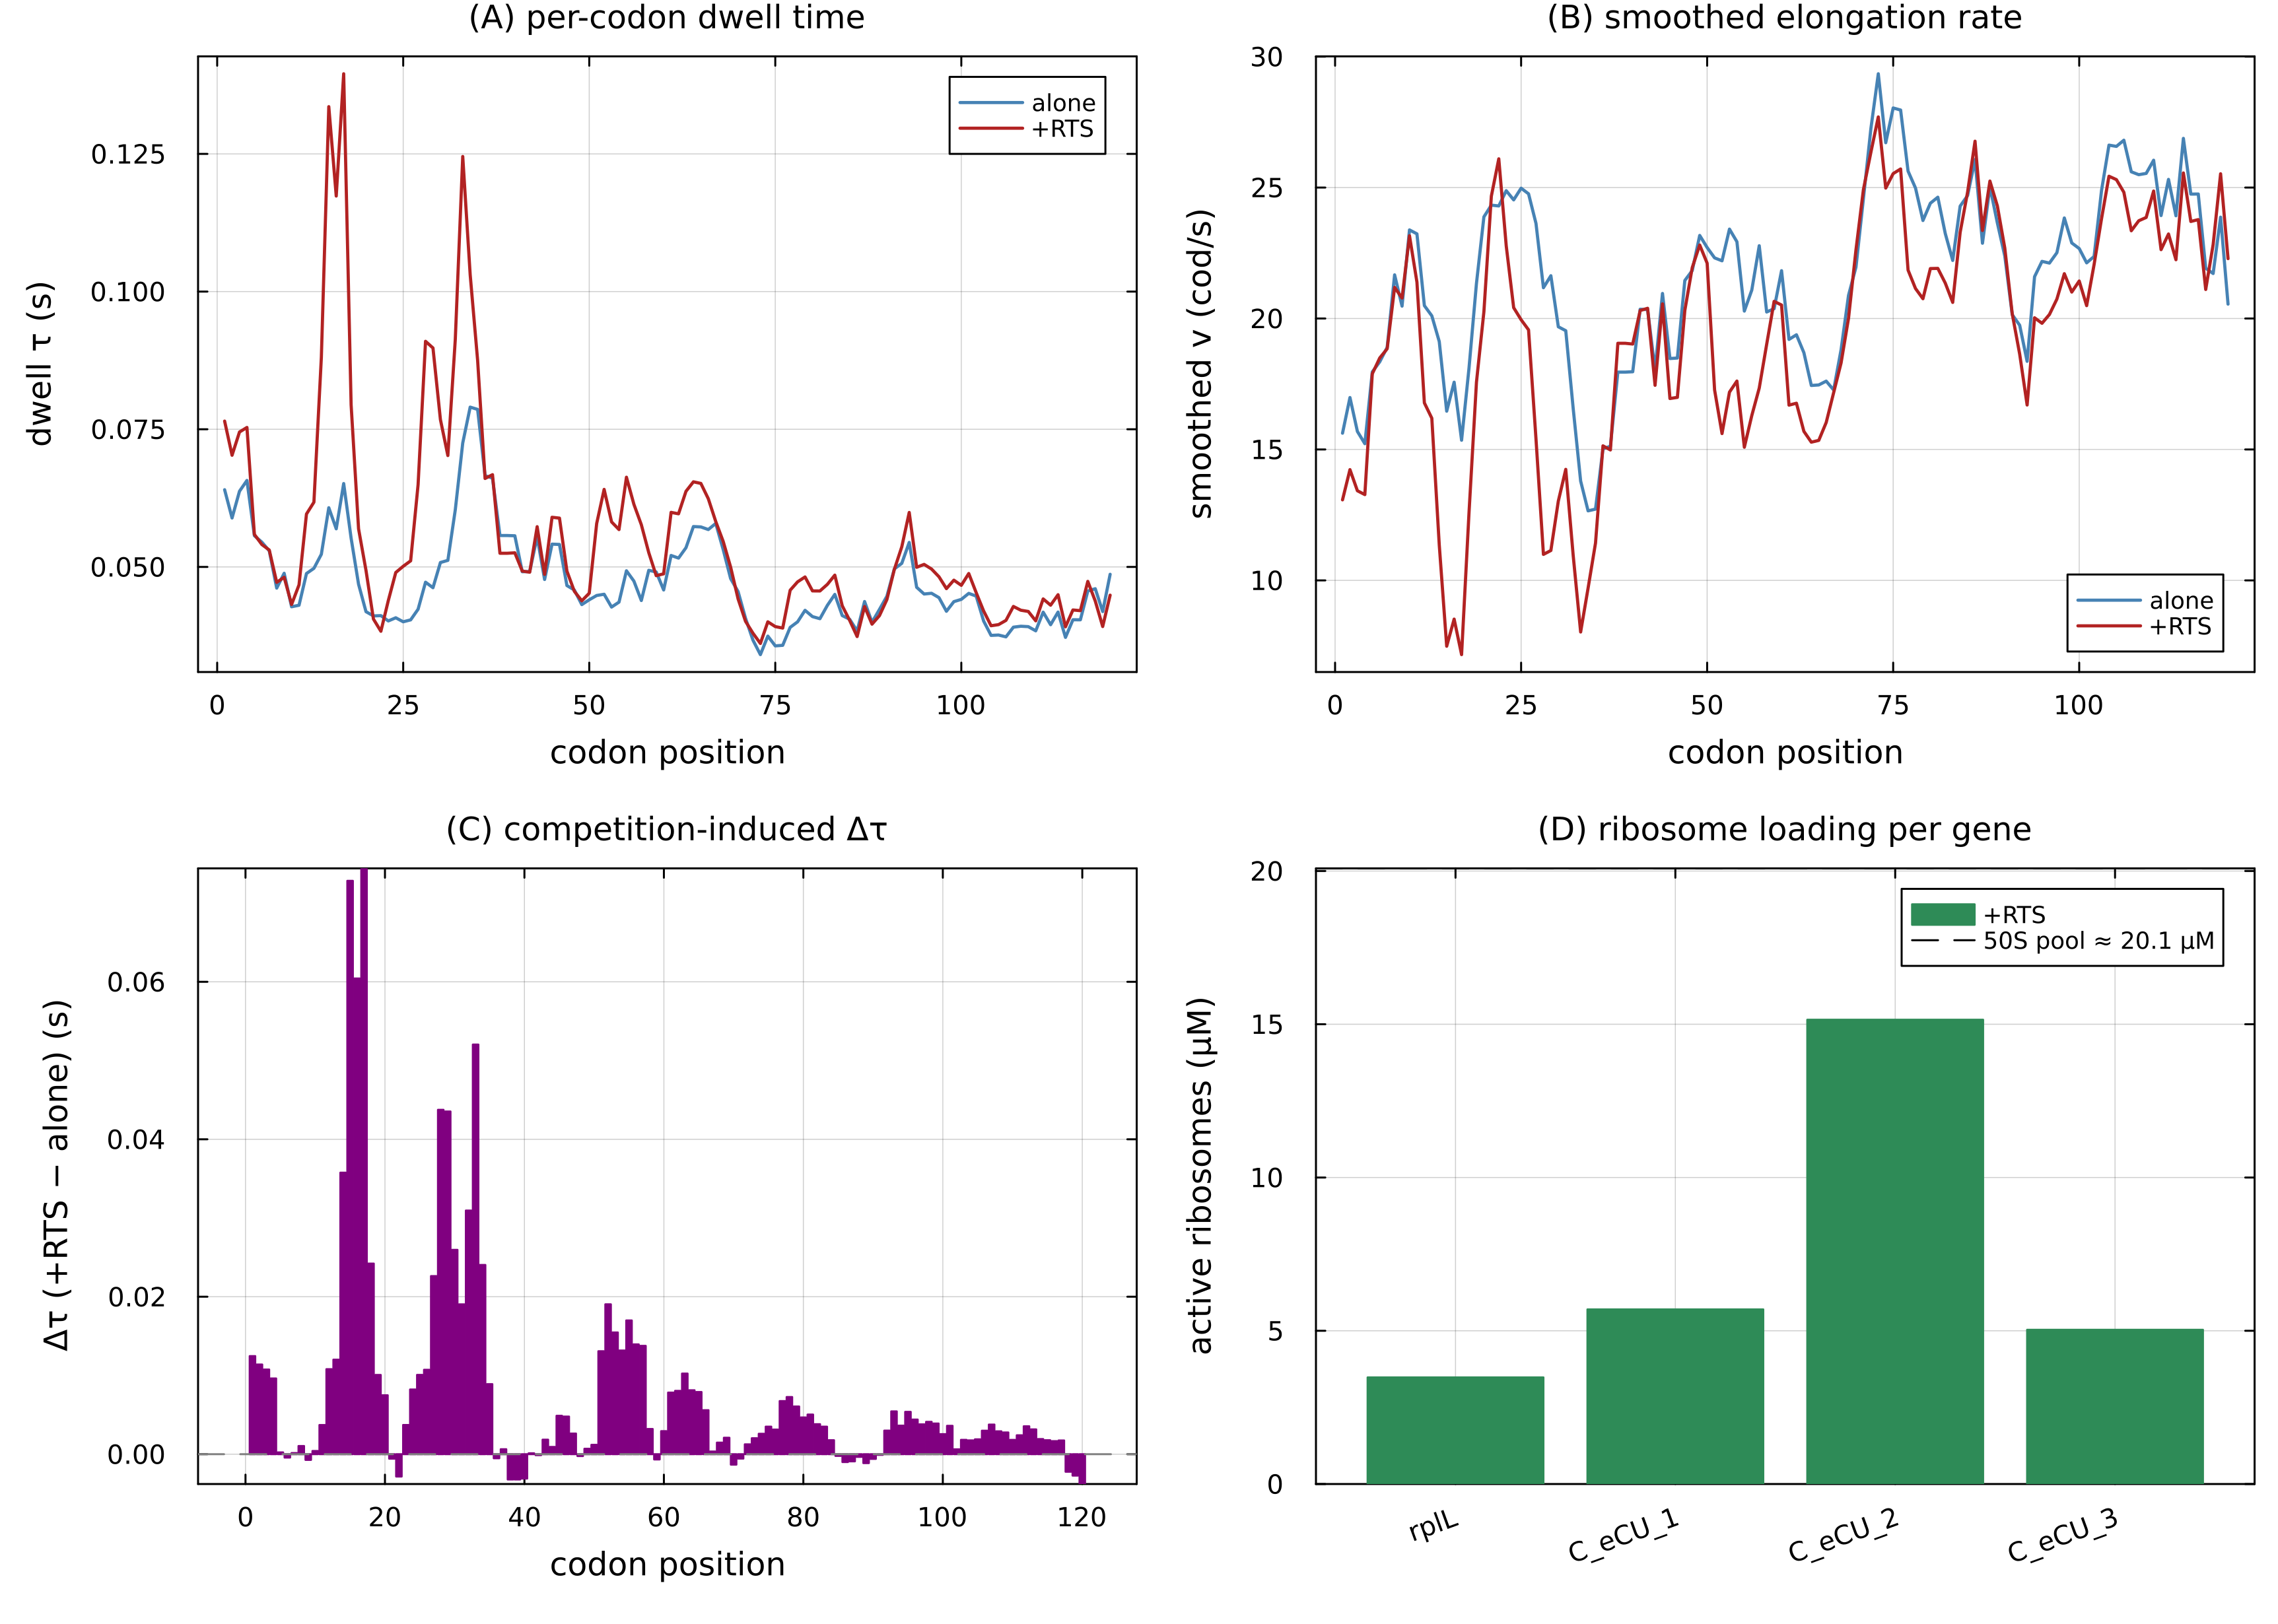

In [9]:
T_SAMPLE = 100.0   # min — elongation snapshot time (paper default)

# ── SPINDLER-FAITHFUL (asymmetric) machinery ─────────────────────────────────
#   alone : DEFAULT scales (all = 1)  → MAIN_single_sequence.m
#   +RTS  : Spindler reference-transcriptome scales (V_IN=75, IF2D=2, ARS=20)
#   The elongation time τ is a single-ribosome transit time (no queuing), so the
#   alone leg's low ribosome load (m=0.001) is expected and does NOT bias τ.
spindler_scale = txtl_types.make_scale(
    V_IN_70SIC_scale = 75.0,
    V_IN_IF2D_scale  = 2.0,
    ARS_scale        = 20.0 .* ones(20),
    Rib_scale        = 1.0,
    EF_scale         = 1,
    tRNA_scale       = 1,
)

m_rplL_alone = 0.001   # Spindler MAIN_single_sequence.m, V_TC_scale=1 → ss≈0.001 µM
m_rplL_rts   = 0.46
m_rts_each   = 0.31
rts_names    = sort(collect(keys(rts_seqs)))

# ── Write the two FASTAs (rplL alone; rplL + 3 eCU) ──────────────────────────
let seqdir = "../data/sequences"
    mkpath(seqdir)
    _clean(s) = replace(replace(strip(s), "\n"=>""), "\r"=>"")
    open(joinpath(seqdir, "spindler_alone_eq.fa"), "w") do io
        println(io, ">rplL"); println(io, _clean(rplL_seq))
    end
    open(joinpath(seqdir, "spindler_rts_eq.fa"), "w") do io
        println(io, ">rplL"); println(io, _clean(rplL_seq))
        for nm in rts_names
            println(io, ">$nm"); println(io, _clean(rts_seqs[nm]))
        end
    end
end

conc_alone = Dict("rplL" => m_rplL_alone)
conc_rts   = Dict{String,Float64}("rplL" => m_rplL_rts)
for nm in rts_names; conc_rts[nm] = m_rts_each; end

# Shared solver + flag settings for BOTH legs (scales differ, see below)
common_solver = (growth_rate    = 1,
                 return_details = true, return_sol = true,
                 static_EFs     = true,
                 spindler_75pct = false,    # applies to both; only visible on +RTS
                 spindler_tx    = false,
                 ode_reltol = 1e-8, ode_abstol = 1e-6, ode_maxiters = 5_000_000)

println("──── alone (rplL, DEFAULT scales = 1) ────")
res_alone = call_model("spindler_alone_eq.fa", ["rplL"], 0;
                       het_mRNA_conc = conc_alone, common_solver...)   # no custom_scale → all scales = 1

println("──── +RTS (rplL + 3 eCU, SPINDLER scales) ────")
res_rts = call_model("spindler_rts_eq.fa", vcat(["rplL"], rts_names), 0;
                     custom_scale = spindler_scale,
                     het_mRNA_conc = conc_rts, common_solver...)

# ── Per-gene active-ribosome loading (same logic as the wrapper) ─────────────
function _active_rib_per_gene(sol, p, t)
    u = sol(clamp(t, sol.t[1], sol.t[end]))
    n_m = p.vectors.n_metab; n_s = p.vectors.n_seq
    per = zeros(n_s)
    for i in 1:n_s
        base = n_m + p.vectors.offsets[i]
        len  = p.vectors.y_codons_lengths[i]
        for j in 5:len; per[i] += max(u[base + j], 0.0); end
    end
    return per
end

rib_alone_vec = _active_rib_per_gene(res_alone.sol, res_alone.p, T_SAMPLE)
rib_rts_vec   = _active_rib_per_gene(res_rts.sol,   res_rts.p,   T_SAMPLE)

sp_alone = spindler_codon_translation_time(res_alone.sol, res_alone.p, "rplL"; t_sample = T_SAMPLE)
sp_rts   = spindler_codon_translation_time(res_rts.sol,   res_rts.p,   "rplL"; t_sample = T_SAMPLE)

res = (
    sp_alone      = sp_alone,
    sp_rts        = sp_rts,
    delta_tau     = sp_rts.tau .- sp_alone.tau,
    delta_total_s = sp_rts.total_time_s - sp_alone.total_time_s,
    pct_longer    = 100 * (sp_rts.total_time_s / sp_alone.total_time_s - 1),
    rib_alone     = sum(rib_alone_vec),
    rib_rts       = sum(rib_rts_vec),
    rib_alone_vec = rib_alone_vec,
    rib_rts_vec   = rib_rts_vec,
    t_sample      = T_SAMPLE,
    m_rplL_alone  = m_rplL_alone,
    m_rplL_rts    = m_rplL_rts,
    m_rts_each    = m_rts_each,
)

a, b = res.sp_alone, res.sp_rts

using Printf, Plots, DataFrames, CSV, Statistics

# ── Shared-pool diagnostics at the snapshot (tRNA / EF pools + ribosomes) ─────
da = collect_pool_diagnostics(res_alone.sol, res_alone.p, T_SAMPLE; primary_gene = "rplL")
db = collect_pool_diagnostics(res_rts.sol,   res_rts.p,   T_SAMPLE; primary_gene = "rplL")
gene_names = vcat(["rplL"], rts_names)
POOL_50S   = 20.086   # µM, 50S subunit (Schmidt 2016, Rib_scale = 1) — ribosome ceiling

# ── Printed summary ───────────────────────────────────────────────────────────
println("\n", "═"^72)
@printf("rplL elongation @ t = %.0f min   (L = %d codons)\n", T_SAMPLE, a.L)
println("─"^72)
@printf("  %-14s %12s %12s %12s\n", "", "alone", "+RTS", "Δ / %")
@printf("  %-14s %12.3f %12.3f %+11.3f s\n", "Στ (s)",      a.total_time_s, b.total_time_s, res.delta_total_s)
@printf("  %-14s %12.3f %12.3f %+11.2f %%\n", "mean v",     a.mean_v, b.mean_v, res.pct_longer)
@printf("  %-14s %12.3f %12.3f\n",            "RIB (µM)",   res.rib_alone, res.rib_rts)
println("─"^72)

# Shared-pool parameter table (the 'other parameters')
@printf("  %-18s %12s %12s\n", "pool / param", "alone", "+RTS")
@printf("  %-18s %12.4f %12.4f\n", "T3_mean (µM)",    da.T3_mean,     db.T3_mean)
@printf("  %-18s %12.4f %12.4f\n", "T3_min (µM)",     da.T3_min,      db.T3_min)
@printf("  %-18s %12.4f %12.4f\n", "charged tRNA",    da.charged_mean,db.charged_mean)
@printf("  %-18s %12.4f %12.4f\n", "EF-Tu·GTP (µM)",  da.EGT,         db.EGT)
@printf("  %-18s %12.4f %12.4f\n", "EF-G·GTP (µM)",   da.EFG,         db.EFG)
@printf("  %-18s %12.4f %12.4f\n", "mean_sat",        da.mean_sat,    db.mean_sat)
@printf("  %-18s %12.4f %12.4f\n", "PRT rplL (µM)",   da.PRT_primary, db.PRT_primary)
println("─"^72)

# Per-gene active-ribosome loading
println("  Active ribosomes per gene (µM):")
@printf("    %-10s %10s %10s\n", "gene", "alone", "+RTS")
for (i, nm) in enumerate(gene_names)
    av = i <= length(res.rib_alone_vec) ? res.rib_alone_vec[i] : NaN
    @printf("    %-10s %10.3f %10.3f\n", nm, av, res.rib_rts_vec[i])
end
@printf("    %-10s %10.3f %10.3f   (50S pool ≈ %.2f µM)\n", "TOTAL", res.rib_alone, res.rib_rts, POOL_50S)
println("═"^72)

# ── Plots ──────────────────────────────────────────────────────────────────────
default(fontfamily="sans-serif", framestyle=:box, dpi=300,
        guidefontsize=11, tickfontsize=9, legendfontsize=8, titlefontsize=11)

pA = plot(1:a.L, a.tau, lw=1.6, c=:steelblue, label="alone",
          xlabel="codon position", ylabel="dwell τ (s)", title="(A) per-codon dwell time")
plot!(pA, 1:a.L, b.tau, lw=1.6, c=:firebrick, label="+RTS")

pB = plot(1:a.L, a.v_smooth, lw=1.6, c=:steelblue, label="alone",
          xlabel="codon position", ylabel="smoothed v (cod/s)", title="(B) smoothed elongation rate")
plot!(pB, 1:a.L, b.v_smooth, lw=1.6, c=:firebrick, label="+RTS")

pC = bar(1:a.L, res.delta_tau, c=:purple, lc=:purple, label=false,
         xlabel="codon position", ylabel="Δτ (+RTS − alone) (s)", title="(C) competition-induced Δτ")
hline!(pC, [0.0], c=:gray, ls=:dash, label=false)

pD = bar(gene_names, res.rib_rts_vec, c=:seagreen, lc=:seagreen, label="+RTS",
         ylabel="active ribosomes (µM)", title="(D) ribosome loading per gene",
         xrotation=20, legend=:topright)
hline!(pD, [POOL_50S], c=:black, ls=:dash, label=@sprintf("50S pool ≈ %.1f µM", POOL_50S))

fig = plot(pA, pB, pC, pD, layout=(2,2), size=(1150, 820),
           left_margin=6Plots.mm, bottom_margin=6Plots.mm)
mkpath("../data/output/figures")
savefig(fig, "../data/output/figures/spindler_rplL_rts_panels.png")
savefig(fig, "../data/output/figures/spindler_rplL_rts_panels.pdf")
display(fig)

# ── CSVs ────────────────────────────────────────────────────────────────────────
codons = [SubString(rplL_seq, 3i-2, 3i) for i in 1:a.L]
detail = DataFrame(pos = 1:a.L, codon = codons,
                   tau_alone = a.tau, tau_rts = b.tau, dtau = res.delta_tau,
                   v_alone = a.v_smooth, v_rts = b.v_smooth)
mkpath("../data/output")
CSV.write("../data/output/spindler_rplL_rts_codon_detail.csv", detail)

summary = DataFrame(
    case         = ["alone", "rts"],
    total_time_s = [a.total_time_s, b.total_time_s],
    mean_v       = [a.mean_v, b.mean_v],
    RIB_active   = [res.rib_alone, res.rib_rts],
    T3_mean      = [da.T3_mean, db.T3_mean],
    EGT          = [da.EGT, db.EGT],
    EFG          = [da.EFG, db.EFG],
    PRT_rplL     = [da.PRT_primary, db.PRT_primary],
    pct_longer   = [0.0, res.pct_longer],
    m_rplL       = [res.m_rplL_alone, res.m_rplL_rts])
CSV.write("../data/output/spindler_rplL_rts_summary.csv", summary)
println("Saved → spindler_rplL_rts_{codon_detail,summary}.csv  +  figures/spindler_rplL_rts_panels.{png,pdf}")